# 02 - Multimodal RAG Pipeline

Going from processed elements to a working, cited Q&A system.

1. **Cleaning text:** the ₹ symbol is stored as "H" by custom PDF fonts
2. **CLIP zero-shot filter:** keeping real charts, dropping photos and logos (537 to 208 images; 130 charts indexed after Gemini skips decorative ones)
3. **Perceptual-hash dedup:** removing repeated images within a report (208 -> 207)
4. **Batched Gemini summaries** for tables and charts: 6 items per call, cached, quota-safe, with model fallback (1,394 to ~150 calls)
5. **Embeddings + ChromaDB:** multi-vector pattern, searching on summaries but answering with the original table or image
6. **Grounded answers:** Gemini answers only from retrieved sources, cites every page, and refuses when the answer isn't there

**Runtime:** T4 GPU recommended (CLIP and embeddings). Needs `GEMINI_API_KEY` in Colab Secrets.

## Setup

In [1]:
# Installing libraries
!pip install -q google-genai chromadb sentence-transformers imagehash

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.0/52.0 kB 1.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.3/23.3 MB 53.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 14.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 278.2/278.2 kB 10.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.5/7.5 MB 46.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 38.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.5/72.5 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.1/140.1 kB 8.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.3/60.3 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 206.3/206.3 kB 11.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 95.7/95.7 kB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.4/69.4 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.6/6

## Loading elements and fixing the ₹ symbol
Cleaning once at load time, so every later step (summaries, embeddings, answers) sees corrected text. The patterns only replace an "H" that stands alone before an amount or "in crore", so words like "Holding" aren't touched.

In [3]:
from google.colab import drive
drive.mount('/content/drive')

import json, re, time, math
from pathlib import Path
import pandas as pd

PROJECT_DIR   = Path("/content/drive/MyDrive/annual-report-rag")
PROCESSED_DIR = PROJECT_DIR / "processed"
CACHE_DIR     = PROJECT_DIR / "cache"
CACHE_DIR.mkdir(exist_ok=True)

# Rupee fix: "(H in Crore)" - "(₹ in Crore)",  "H 1,698 crore" - "₹ 1,698 crore"
RUPEE_UNIT = re.compile(r"(?<![A-Za-z])H(?=\s*in\s+(?i:crore|lakh|million|billion|thousand))")
RUPEE_AMT  = re.compile(r"(?<![A-Za-z])H\s?(?=\d[\d,]*(?:\.\d+)?\s*(?i:crore|lakh|cr|mn|bn)\b)")

def fix_rupee(s):
    s = RUPEE_UNIT.sub("₹", s or "")
    return RUPEE_AMT.sub("₹ ", s)

elements = []
for f in sorted(PROCESSED_DIR.glob("*.json")):
    for e in json.loads(f.read_text()):
        e["content"] = fix_rupee(e.get("content", ""))
        e["caption"] = fix_rupee(e.get("caption", ""))
        e["year"] = str(e["year"])
        elements.append(e)

by_id = {e["id"]: e for e in elements}
print(pd.Series([e["type"] for e in elements]).value_counts())

t = next(e for e in elements if e["type"] == "table" and "₹" in e["content"])
print("\n₹ fix example:", t["content"][:300])

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
text     3127
table     857
image     537
Name: count, dtype: int64

₹ fix example: | Strategy                            | Strategy in Action                                                                                       |
|-------------------------------------|----------------------------------------------------------------------------------------------------------|
| 1 Fo


## Connecting to Gemini
Model names change over time (two models were retired during this project), so the available models are listed and the first one that works is picked.

In [4]:
from google import genai
from google.genai import types
from google.colab import userdata

client = genai.Client(api_key=userdata.get("GEMINI_API_KEY"))

print("Available Flash models:")
for m in client.models.list():
    if "flash" in m.name:
        print("  ", m.name)

def first_working(candidates):
    for name in candidates:
        try:
            r = client.models.generate_content(model=name, contents="Reply with exactly: ok")
            print(f" {name}: {r.text.strip()}")
            return name
        except Exception as ex:
            print(f" {name}: {str(ex)[:120]}")
    raise RuntimeError("No candidate model worked, paste me the errors above")

print("Answer / chart model:")
ANSWER_MODEL = first_working(["gemini-3.8-flash", "gemini-3.7-flash", "gemini-3.5-flash"])

print("\nTable summary model:")
SUMMARY_MODEL = first_working(["gemini-3.5-flash-lite", "gemini-3.1-flash-lite", ANSWER_MODEL])

print(f"\nUsing SUMMARY_MODEL={SUMMARY_MODEL}, ANSWER_MODEL={ANSWER_MODEL}")

Available Flash models:
   models/gemini-2.5-flash
   models/gemini-2.5-flash-preview-tts
   models/gemini-flash-latest
   models/gemini-flash-lite-latest
   models/gemini-2.5-flash-lite
   models/gemini-2.5-flash-image
   models/gemini-3-flash-preview
   models/gemini-3.1-flash-lite-preview
   models/gemini-3.1-flash-lite
   models/gemini-3.1-flash-image-preview
   models/gemini-3.1-flash-image
   models/gemini-3.1-flash-lite-image
   models/gemini-3.5-flash
   models/gemini-3.5-flash-lite
   models/gemini-omni-flash-preview
   models/gemini-omni-1.1-flash
   models/gemini-3.6-flash
   models/gemini-3.7-flash
   models/gemini-3.8-flash
   models/gemini-3.1-flash-tts-preview
   models/gemini-3.8-flash-tts
   models/gemini-3.8-flash-lite-tts
   models/gemini-2.5-flash-native-audio-latest
   models/gemini-2.5-flash-native-audio-preview-09-2025
   models/gemini-2.5-flash-native-audio-preview-12-2025
   models/gemini-3.1-flash-live-preview
Answer / chart model:
 gemini-3.8-flash: ok

Table

## CLIP chart filter
Zero-shot classification: CLIP compares each image with text labels ("a bar chart", "a company logo", ...). The probabilities of the chart-like labels are summed into one "is this a chart?" score. Scores are cached on Drive.

In [5]:
import torch
from PIL import Image
from transformers import CLIPModel, CLIPProcessor

device = "cuda" if torch.cuda.is_available() else "cpu"
clip = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(device).eval()
clip_proc = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

CHART_LABELS = ["a bar chart", "a line graph", "a pie chart or donut chart",
                "a table of numbers", "an infographic with numbers and statistics",
                "a diagram or flowchart"]
JUNK_LABELS  = ["a photograph of people", "a photograph of a building or landscape",
                "a company logo", "a decorative illustration", "a small icon",
                "a portrait photo of a person", "a photograph of products or objects"]
LABELS = CHART_LABELS + JUNK_LABELS

CLIP_CACHE = CACHE_DIR / "clip_scores.json"
clip_scores = json.loads(CLIP_CACHE.read_text()) if CLIP_CACHE.exists() else {}

images = [e for e in elements if e["type"] == "image"]
todo = [e for e in images if e["id"] not in clip_scores]
print(f"{len(images)} images, {len(todo)} to score")

with torch.no_grad():
    for i in range(0, len(todo), 32):
        batch = todo[i:i + 32]
        ims = [Image.open(e["image_path"]).convert("RGB") for e in batch]
        inputs = clip_proc(text=LABELS, images=ims, return_tensors="pt", padding=True).to(device)
        probs = clip(**inputs).logits_per_image.softmax(dim=-1)        # image vs every label
        chart_prob = probs[:, :len(CHART_LABELS)].sum(dim=1).tolist()   # P(it's a chart-like thing)
        for e, p in zip(batch, chart_prob):
            clip_scores[e["id"]] = round(p, 4)

CLIP_CACHE.write_text(json.dumps(clip_scores))
print("done")

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

...

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

537 images, 0 to score
done


## Checking the filter and picking a threshold
Rejecting a real chart loses information; keeping a photo wastes a Gemini call. The borderline row shows images closest to the threshold.

kept 208 / rejected 329


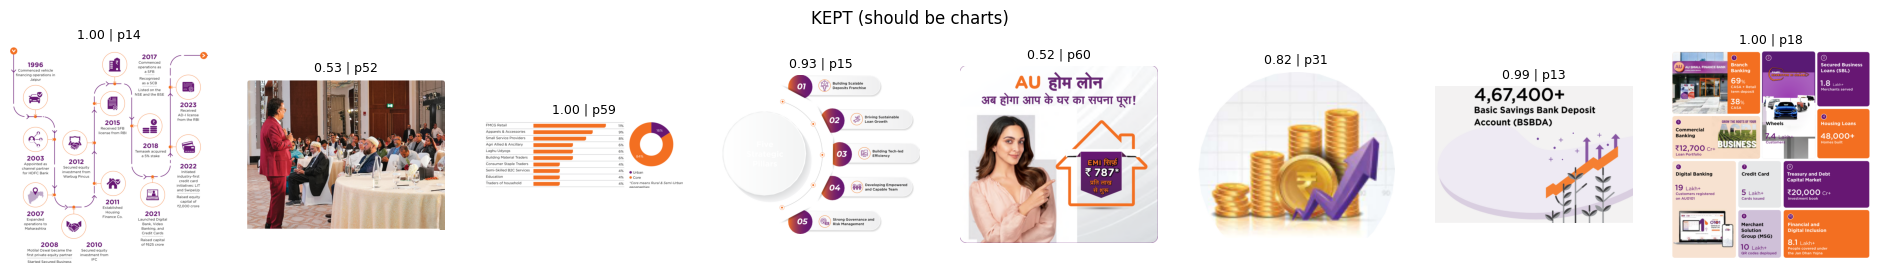

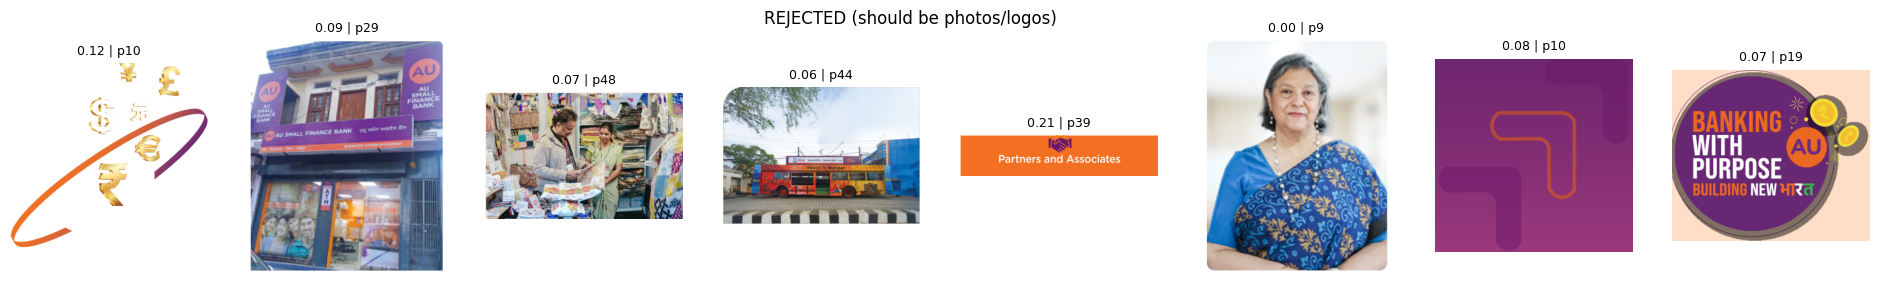

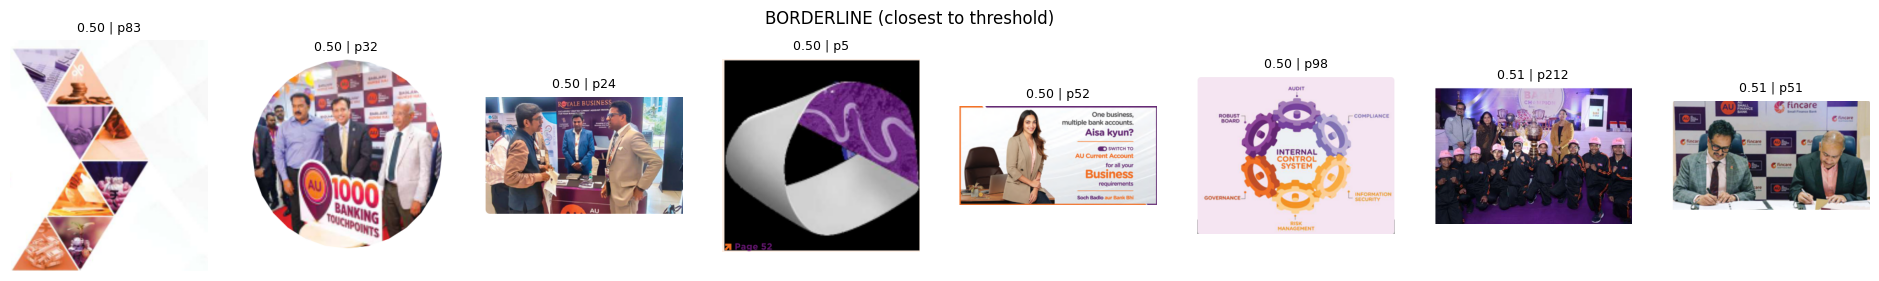

In [6]:
import matplotlib.pyplot as plt

CHART_THRESHOLD = 0.5      # raise it if junk gets through; lower it if charts get rejected

def show_grid(items, title, n=8):
    items = items[:n]
    if not items:
        print(f"{title}: none"); return
    fig, axes = plt.subplots(1, len(items), figsize=(3 * len(items), 3))
    for ax, e in zip(axes if len(items) > 1 else [axes], items):
        ax.imshow(Image.open(e["image_path"])); ax.axis("off")
        ax.set_title(f"{clip_scores[e['id']]:.2f} | p{e['page']}", fontsize=9)
    fig.suptitle(title); plt.show()

import random
kept     = [e for e in images if clip_scores[e["id"]] >= CHART_THRESHOLD]
rejected = [e for e in images if clip_scores[e["id"]] <  CHART_THRESHOLD]
print(f"kept {len(kept)} / rejected {len(rejected)}")

show_grid(random.sample(kept, min(8, len(kept))), "KEPT (should be charts)")
show_grid(random.sample(rejected, min(8, len(rejected))), "REJECTED (should be photos/logos)")
borderline = sorted(images, key=lambda e: abs(clip_scores[e["id"]] - CHART_THRESHOLD))
show_grid(borderline, "BORDERLINE (closest to threshold)")

## Removing duplicate images
a perceptual hash is a fingerprint of how an image looks. Near-identical images get hashes that differ by only a few bits. We only compare within the same report, because charts from different years can share a layout but contain different numbers.

In [7]:
import imagehash

def dedupe(items, max_dist=3):
    unique, seen = [], {}          # seen: doc_id - list of (id, hash)
    for e in items:
        h = imagehash.phash(Image.open(e["image_path"]))
        prior = seen.setdefault(e["doc_id"], [])
        dup = next((pid for pid, ph in prior if h - ph <= max_dist), None)
        if dup:
            e["duplicate_of"] = dup
        else:
            prior.append((e["id"], h))
            unique.append(e)
    return unique

unique_images = dedupe(kept)
print(f"{len(kept)} kept to {len(unique_images)} after removing duplicates")

208 kept to 207 after removing duplicates


## Planning the Gemini calls
Tiny tables (fewer than 3 rows or columns) are embedded directly without a summary.

In [8]:
def table_needs_summary(t):
    r, c = t["shape"]
    return r >= 3 and c >= 3          # tiny tables are embedded directly, no summary

tables = [e for e in elements if e["type"] == "table"]
tables_to_summarize = [t for t in tables if table_needs_summary(t)]

BATCH = 6
calls = math.ceil(len(tables_to_summarize) / BATCH) + math.ceil(len(unique_images) / BATCH)
print(f"Tables to summarize : {len(tables_to_summarize)} (of {len(tables)})")
print(f"Images to summarize : {len(unique_images)} (of {len(images)})")
print(f"Estimated Gemini calls: {calls}  (was {len(tables) + len(images)} without filtering/batching)")

Tables to summarize : 693 (of 857)
Images to summarize : 207 (of 537)
Estimated Gemini calls: 151  (was 1394 without filtering/batching)


## The batched, quota-safe summarizer
- **Batching:** 6 items per call, returned as JSON with each item's ID
- **Text vs image:** digital tables are sent as Markdown (exact numbers); charts and scanned tables as images
- **Resilience:** per-minute limits wait and retry, the daily limit stops cleanly with progress saved, code bugs stop immediately, and 3 failed batches in a row trip a circuit breaker

In [9]:
SUMMARY_CACHE = CACHE_DIR / "summaries.json"
summaries = json.loads(SUMMARY_CACHE.read_text()) if SUMMARY_CACHE.exists() else {}

def save_summaries():
    SUMMARY_CACHE.write_text(json.dumps(summaries, ensure_ascii=False, indent=1))

SUMMARY_PROMPT = """You summarize content from Indian company annual reports so a search engine can find it.
You will receive {n} items. Each starts with a line 'ITEM <id> | ...source info...'.
For EACH item write a 3-6 sentence summary stating:
- what it is (type of table/chart) and its subject,
- the key metrics with exact numbers, units (₹ crore, %, etc.) and periods (e.g. FY 2023-24),
- any notable trend or comparison.
Note: a capital 'H' right before amounts or before 'in crore' is the rupee symbol (₹).
If an item is decorative or contains no real information, set its summary to "SKIP".
Return ONLY a JSON list: [{{"id": "<id>", "summary": "<summary>"}}]"""

class DailyQuotaExceeded(Exception):
    pass

def item_header(e):
    return (f"ITEM {e['id']} | {e['company']} | FY{e['year']} | page {e['page']} "
            f"| caption: {e.get('caption', '')[:200]}")

def build_contents(batch, kind):
    contents = [SUMMARY_PROMPT.format(n=len(batch))]
    for e in batch:
        contents.append(item_header(e))
        use_text = (kind == "table" and e.get("parse_mode", "digital") == "digital") or not e.get("image_path")
        if use_text:
            contents.append(e["content"][:6000])          # digital tables: Markdown is exact
        else:
            contents.append(Image.open(e["image_path"]))  # charts + scanned tables: Gemini looks at the image
    return contents

In [10]:
class DailyQuotaExceeded(Exception):
    pass

def call_gemini(contents, model=None, max_retries=5):
    model = model or SUMMARY_MODEL
    for attempt in range(max_retries):
        try:
            r = client.models.generate_content(
                model=model, contents=contents,
                config=types.GenerateContentConfig(temperature=0, response_mime_type="application/json"))
            out = json.loads(r.text)
            return out if isinstance(out, list) else out.get("items", [out])
        except (NameError, AttributeError, TypeError, FileNotFoundError):
            raise                                    # code/setup bug -> stop immediately
        except json.JSONDecodeError:
            print("   bad JSON, retrying"); time.sleep(5)
        except Exception as ex:
            msg = str(ex)
            if "429" in msg or "RESOURCE_EXHAUSTED" in msg:
                if "PerDay" in msg:
                    raise DailyQuotaExceeded(msg)
                wait = 30 * (attempt + 1)
                print(f"   per-minute limit hit, waiting {wait}s"); time.sleep(wait)
            else:
                print(f"   API error: {msg[:200]}"); time.sleep(10)
    return None

def run_summaries(items, kind, batch_size=BATCH, sleep_s=7, max_failed_batches=3):
    assert "client" in globals(), "Run Cell 3 first: Gemini client is not set up"
    model = ANSWER_MODEL if kind == "image" else SUMMARY_MODEL
    todo = [e for e in items if e["id"] not in summaries]
    print(f"{kind}: {len(todo)} remaining (model: {model})")
    failed_in_a_row = 0
    try:
        for i in range(0, len(todo), batch_size):
            batch = todo[i:i + batch_size]
            result = call_gemini(build_contents(batch, kind), model=model)
            if not result:
                failed_in_a_row += 1
                if failed_in_a_row >= max_failed_batches:
                    print(f"{failed_in_a_row} batches failed in a row, stopping. Check the errors above.")
                    break
                continue
            failed_in_a_row = 0
            for r in result:
                if isinstance(r, dict) and r.get("id") in by_id:
                    summaries[r["id"]] = fix_rupee(r.get("summary", ""))
            save_summaries()
            done = sum(e["id"] in summaries for e in items)
            print(f"   {done}/{len(items)} done")
            time.sleep(sleep_s)
    except DailyQuotaExceeded:
        save_summaries()
        print("Daily quota reached, progress is saved. Rerun this cell tomorrow to continue.")

print("Summarizer ready")

Summarizer ready


## Summarizing tables (Flash-Lite)

In [11]:
run_summaries(tables_to_summarize, "table")

table: 0 remaining (model: gemini-3.5-flash-lite)


In [12]:
table_ids = {t["id"] for t in tables_to_summarize}
done  = [i for i in table_ids if i in summaries]
skips = [i for i in done if summaries[i] == "SKIP"]

print(f"Summarized: {len(done)}/{len(table_ids)} | missing: {len(table_ids) - len(done)} | SKIP: {len(skips)}")

import random
for tid in random.sample([i for i in done if i not in skips], 3):
    t = by_id[tid]
    print(f"\n--- {tid} (page {t['page']}, shape {t['shape']}) ---")
    print(summaries[tid])

Summarized: 693/693 | missing: 0 | SKIP: 52

--- au_small_finance_bank_2025_p81_table_3 (page 83, shape [5, 3]) ---
This table details the composition of another board committee at AU Small Finance Bank for FY2025. It comprises four independent directors led by Mr. M. S. Sriram as Chairperson. The committee members consist of Mr. Pushpinder Singh, Ms. Malini Thadani, and Mr. H. R. Khan.

--- au_small_finance_bank_2023_table_49 (page 140, shape [3, 3]) ---
This table presents the remuneration details of key managerial personnel for AU Small Finance Bank for FY 2022-23. It lists the fixed pay (including perquisites) and variable pay of previous years paid during the financial year for key executives. Specifically, Mr. Sanjay Agarwal, MD & CEO, received a fixed pay of 233 lakh and variable pay of 89 lakh, while Mr. Uttam Tibrewal, Whole-Time Director, received a fixed pay of 202 lakh and variable pay of 38 lakh.

--- au_small_finance_bank_2024_p161_table_19 (page 165, shape [11, 7]) ---
T

## Summarizing charts, with a fallback chain across models
Free-tier quotas are per model, so when one model hits its daily limit the job continues on the next, resuming from the cache.

In [13]:
for m in ["gemini-3.7-flash", "gemini-3.6-flash", "gemini-3.5-flash-lite"]:
    ANSWER_MODEL = m
    print(f"\n    Trying {m}    ")
    run_summaries(unique_images, "image")
    if all(e["id"] in summaries for e in unique_images):
        print("\n All charts summarized")
        break


    Trying gemini-3.7-flash    
image: 0 remaining (model: gemini-3.7-flash)

 All charts summarized


In [14]:
# Showing sample chart summaries
print("\nSample summaries:")
for e in unique_images[:3]:
    if e["id"] in summaries:
        print(f" p{e['page']}: {summaries[e['id']][:300]}\n")


Sample summaries:
 p4: This infographic presents an overview of AU Small Finance Bank's primary business segments and operating verticals for FY 2022-23. It categorizes the bank's key offerings into ten distinct areas: Branch Banking, Wheels (vehicle finance), Secured Business Loans (SBL), Housing Loans, and Commercial Ba

 p5: SKIP

 p5: SKIP



## Embedding everything
The text that gets embedded includes the company, fiscal year and page, so search knows which report each piece came from.

In [15]:
import chromadb, shutil
from sentence_transformers import SentenceTransformer

embedder = SentenceTransformer("BAAI/bge-small-en-v1.5", device=device)
unique_ids = {e["id"] for e in unique_images}

def embed_text(e):
    head = f"{e['company'].replace('_', ' ')} annual report FY{e['year']}, page {e['page']}."
    s = summaries.get(e["id"], "")
    if e["type"] == "text":
        return f"{head}\n{e['content']}"
    if e["type"] == "table":
        return f"Table. {head} {e.get('caption', '')}\n{s}\n{e['content'][:2000]}"
    return f"Chart/figure. {head} {e.get('caption', '')}\n{s}"

index_items = []
for e in elements:
    s = summaries.get(e["id"], "")
    if s == "SKIP":
        continue
    if e["type"] == "image" and (e["id"] not in unique_ids or not s):
        continue                              # only charts that passed CLIP + have a summary
    index_items.append(e)

texts = [embed_text(e) for e in index_items]
vecs = embedder.encode(texts, batch_size=64, normalize_embeddings=True, show_progress_bar=True)
print("embeddings:", vecs.shape)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/94.8k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/743 [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/64 [00:00<?, ?it/s]

embeddings: (4059, 384)


## Building ChromaDB and the docstore (multi-vector pattern)
- **Chroma** stores what we search on: embeddings of summaries, headings and table previews
- **The docstore** holds what we answer with: the full table, the full chunk, the image path
- The same ID links the two. Chroma is built on local disk and copied to Drive, because databases are slow and unreliable directly on Drive. Clearing Chroma's client cache avoids an "unable to open database file" error from stale connections.

In [19]:
import numpy as np, time, shutil, chromadb

# 1. Save the embeddings first, so they're never lost again
np.save(CACHE_DIR / "vecs.npy", vecs)
(CACHE_DIR / "index_ids.json").write_text(json.dumps([e["id"] for e in index_items]))
print("Embeddings saved to Drive:", vecs.shape)

# 2. Clear Chroma's cached connections, and use a fresh folder name
try:
    from chromadb.api.client import SharedSystemClient
    SharedSystemClient.clear_system_cache()
except Exception:
    pass
CHROMA_LOCAL = f"/content/chroma_{int(time.time())}"
chroma = chromadb.PersistentClient(path=CHROMA_LOCAL)
col = chroma.get_or_create_collection("annual_reports", metadata={"hnsw:space": "cosine"})

# 3. Add everything (same as before)
for i in range(0, len(index_items), 1000):
    b = index_items[i:i + 1000]
    col.add(
        ids=[e["id"] for e in b],
        embeddings=vecs[i:i + 1000].tolist(),
        documents=texts[i:i + 1000],
        metadatas=[{"type": e["type"], "company": e["company"], "year": e["year"],
                    "doc_id": e["doc_id"], "page": int(e["page"]) if e["page"] is not None else -1}
                   for e in b],
    )

# 4. Docstore + copy the database to Drive
docstore = {e["id"]: {**e, "summary": summaries.get(e["id"], "")} for e in index_items}
(PROJECT_DIR / "docstore.json").write_text(json.dumps(docstore, ensure_ascii=False))

CHROMA_DRIVE = PROJECT_DIR / "chroma"
shutil.rmtree(CHROMA_DRIVE, ignore_errors=True)
shutil.copytree(CHROMA_LOCAL, CHROMA_DRIVE)

print(f"Indexed {col.count()} items:",
      pd.Series([e["type"] for e in index_items]).value_counts().to_dict())

Embeddings saved to Drive: (4059, 384)
Indexed 4059 items: {'text': 3127, 'table': 802, 'image': 130}


## Understanding the question and retrieving
- **Metadata filtering:** company and fiscal year are parsed from the question ("FY 2023-24" -> 2024) and applied before similarity search, so an FY24 question can't pull FY23 numbers
- **Query prefix:** bge's retrieval instruction, which the model was trained with

In [21]:
QUERY_PREFIX = "Represent this sentence for searching relevant passages: "   # bge's query instruction
COMPANIES = sorted({e["company"] for e in elements})
YEARS = sorted({e["year"] for e in elements})
ALIASES = {c: [c.replace("_", " ")] for c in COMPANIES}
ALIASES.setdefault("au_small_finance_bank", []).extend(["au bank", "au sfb"])   # add your own nicknames

def find_years(q):
    ys, q = set(), q.lower()
    for m in re.finditer(r"(20\d{2})\s*[-–/]\s*(\d{2,4})", q):      # "2023-24" -> 2024
        end = m.group(2); ys.add(end if len(end) == 4 else "20" + end)
    q = re.sub(r"(20\d{2})\s*[-–/]\s*(\d{2,4})", " ", q)
    for m in re.finditer(r"fy\s*'?(\d{2,4})\b", q):                 # "FY24" -> 2024
        y = m.group(1); ys.add(y if len(y) == 4 else "20" + y)
    q = re.sub(r"fy\s*'?(\d{2,4})\b", " ", q)
    ys.update(re.findall(r"\b(20\d{2})\b", q))                      # plain "2024"
    return sorted(y for y in ys if y in YEARS)

def parse_query(q):
    ql = q.lower()
    company = next((c for c, names in ALIASES.items() if any(n in ql for n in names)), None)
    return company, find_years(q)

def retrieve(q, k=8, company=None, years=None):
    conds = []
    if company:
        conds.append({"company": company})
    if years:
        conds.append({"year": years[0]} if len(years) == 1 else {"year": {"$in": years}})
    where = None if not conds else conds[0] if len(conds) == 1 else {"$and": conds}

    qv = embedder.encode([QUERY_PREFIX + q], normalize_embeddings=True)[0].tolist()
    res = col.query(query_embeddings=[qv], n_results=k, where=where)
    hits = []
    for id_, dist in zip(res["ids"][0], res["distances"][0]):
        h = dict(docstore[id_]); h["score"] = round(1 - dist, 3)
        hits.append(h)
    return hits

q = "What was the gross NPA closing balance in FY 2023-24?"
company, years = parse_query(q)
print("parsed:", company, years)
for h in retrieve(q, k=5, company=company, years=years):
    print(f"{h['score']:.3f} | {h['type']:5} | FY{h['year']} p{h['page']} | {(h['summary'] or h['content'])[:100]}")

parsed: None ['2024']
0.755 | text  | FY2024 p149 | Schedules
 Crore).March 31, 2023 Gross NPAs = 141.96. , (₹ in Crore).% of Gross NPAs to Total Advanc
0.745 | table | FY2024 p148 | This table presents the movement of gross standard advances, NPAs, and provisions for AU Small Finan
0.742 | table | FY2024 p148 | This table presents the movement of gross standard advances, non-performing advances (NPAs), and pro
0.724 | table | FY2024 p54 | This table details the loan provisions and coverage ratios for AU Small Finance Bank for FY 2023-24.
0.717 | text  | FY2024 p122 | 1 Identification of Non-Performing Advances and Provisioning for Advances
(Refer Schedule 9 to the f


## Generating grounded answers
The prompt forces the model to use only the sources, cite every fact, and say "not found" instead of guessing. Charts are sent as real images, so generation is multimodal too. Calls use exponential backoff and fall back to another model when one is overloaded or out of quota.

In [22]:
from IPython.display import display, Markdown

ANSWER_PROMPT = """You are a financial analyst assistant answering questions about company annual reports.
Rules:
- Use ONLY the sources provided below. Never use outside knowledge.
- Quote exact numbers with their units (₹ crore, %, etc.) and fiscal year.
- Cite every fact like [AU Small Finance Bank FY2024, p.148].
- If the sources don't contain the answer, reply: "I couldn't find this in the provided reports."
- Keep it concise: a direct answer first, then 1-3 supporting points."""

ANSWER_MODELS = ["gemini-3.8-flash", "gemini-3.7-flash", "gemini-3.6-flash"]

def generate_with_fallback(contents, models=ANSWER_MODELS, retries_per_model=3):
    for model in models:
        for attempt in range(retries_per_model):
            try:
                r = client.models.generate_content(
                    model=model, contents=contents,
                    config=types.GenerateContentConfig(temperature=0))
                return r.text, model
            except Exception as ex:
                msg = str(ex)
                if "503" in msg or "UNAVAILABLE" in msg:
                    wait = 5 * 2 ** attempt                  # 5s, 10s, 20s
                    print(f"   {model} overloaded, retry in {wait}s")
                    time.sleep(wait)
                elif "429" in msg or "RESOURCE_EXHAUSTED" in msg:
                    print(f"   {model} out of quota, trying next model")
                    break                                    # no point retrying this model
                else:
                    raise                                    # real bug -> show it
        # fall through to next model
    raise RuntimeError("All models unavailable right now, try again in a few minutes")

def answer(q, k=8, show=True):
    company, years = parse_query(q)
    hits = retrieve(q, k=k, company=company, years=years)

    contents = [ANSWER_PROMPT, f"QUESTION: {q}", "SOURCES:"]
    for i, h in enumerate(hits, 1):
        src = f"[{h['company'].replace('_', ' ').title()} FY{h['year']}, p.{h['page']}]"
        if h["type"] == "image":
            contents += [f"Source {i} {src}: chart. Summary: {h['summary']}",
                         Image.open(h["image_path"])]
        elif h["type"] == "table":
            contents.append(f"Source {i} {src}: table\n{h['content'][:6000]}")
            if h.get("parse_mode", "digital") != "digital" and h.get("image_path"):
                contents.append(Image.open(h["image_path"]))
        else:
            contents.append(f"Source {i} {src}: text\n{h['content']}")

    text, used_model = generate_with_fallback(contents)

    if show:
        display(Markdown(f"**Q: {q}**\n\n{text}"))
        print(f"model: {used_model} | filters - company: {company}, years: {years}")
        for h in hits:
            print(f"  {h['score']:.3f} | {h['type']:5} | FY{h['year']} p{h['page']}")
        for h in [h for h in hits if h["type"] == "image"][:2]:
            display(Image.open(h["image_path"]))
    return text, hits

## Testing the system

In [23]:
answer("What was the gross NPA closing balance in FY 2023-24?");

**Q: What was the gross NPA closing balance in FY 2023-24?**

The gross NPA (Total Non-Performing Advances) closing balance in FY 2023-24 was **₹ 1,237.40 Crore** [Au Small Finance Bank FY2024, p.148].

**Supporting details:**
* The closing balance comprises sub-standard advances of ₹ 844.53 Crore, doubtful advances of ₹ 387.77 Crore, and loss assets of ₹ 5.10 Crore [Au Small Finance Bank FY2024, p.148].
* During FY 2023-24, additions to gross NPAs were ₹ 1,698.19 Crore and reductions were ₹ 1,442.10 Crore, starting from an opening balance of ₹ 981.31 Crore [Au Small Finance Bank FY2024, p.148].
* As of March 31, 2024, the Gross NPA ratio stood at 1.67% of gross advances [Au Small Finance Bank FY2024, p.122, p.149].

model: gemini-3.8-flash | filters - company: None, years: ['2024']
  0.755 | text  | FY2024 p149
  0.745 | table | FY2024 p148
  0.742 | table | FY2024 p148
  0.724 | table | FY2024 p54
  0.717 | text  | FY2024 p122
  0.715 | table | FY2024 p149
  0.711 | table | FY2024 p53
  0.710 | table | FY2024 p150


In [24]:
answer("How did total advances change between FY23 and FY24?");

**Q: How did total advances change between FY23 and FY24?**

Total Gross Advances increased by ₹ 14,841 crore (or 25.09%) from ₹ 59,158 crore in FY 2022-23 to ₹ 73,999 crore in FY 2023-24 [Au Small Finance Bank FY2024, p.54].

**Supporting details:**
* **Gross Advances & Assigned Loans:** Total Gross Advances grew from ₹ 59,158 crore in FY 2022-23 to ₹ 73,999 crore in FY 2023-24, while assigned loans rose from ₹ 4,914 crore to ₹ 8,176 crore over the same period [Au Small Finance Bank FY2024, p.54].
* **Concentration of Advances:** Advances to the twenty largest borrowers decreased from ₹ 1,669.94 crore as of March 31, 2023 to ₹ 1,588.46 crore as of March 31, 2024, decreasing their share from 2.32% to 1.65% of the bank's total advances [Au Small Finance Bank FY2024, p.152].

model: gemini-3.8-flash | filters - company: None, years: ['2023', '2024']
  0.704 | table | FY2023 p73
  0.686 | table | FY2023 p260
  0.677 | text  | FY2024 p152
  0.672 | table | FY2024 p152
  0.669 | table | FY2023 p261
  0.668 | table | FY2023 p267
  0.666 | text  | FY2023 p267
  0.666 | table | FY2024 p54


In [25]:
answer("Who is the CEO of Google?");

**Q: Who is the CEO of Google?**

I couldn't find this in the provided reports.

model: gemini-3.8-flash | filters - company: None, years: []
  0.569 | text  | FY2023 p314
  0.542 | text  | FY2025 p11
  0.536 | table | FY2025 p97
  0.533 | text  | FY2024 p97
  0.530 | text  | FY2025 p94
  0.530 | table | FY2024 p91
  0.529 | table | FY2024 p107
  0.525 | text  | FY2025 p79


**Q: Show me the business segments of AU Small Finance Bank in FY2023**

In FY2023 (year ended March 31, 2023), AU Small Finance Bank reported four primary business segments under its regulatory segment reporting, along with ten core operational business verticals [Au Small Finance Bank FY2023, p.179, p.284].

**Supporting details:**

1. **Regulatory Business Segments & FY2023 Revenues:**
   * **Retail banking:** ₹7,234.12 crore [Au Small Finance Bank FY2023, p.284]
   * **Treasury:** ₹1,208.60 crore [Au Small Finance Bank FY2023, p.284]
   * **Wholesale banking:** ₹717.57 crore [Au Small Finance Bank FY2023, p.284]
   * **Other banking operations:** ₹79.58 crore [Au Small Finance Bank FY2023, p.284]

2. **Core Operational Business Segments/Verticals for FY 2022-23:** 
   The bank outlines 10 operational verticals: (1) Branch Banking, (2) Wheels, (3) Secured Business Loans, (4) Housing Loans, (5) Commercial Banking, (6) Digital Banking, (7) Credit Cards, (8) Merchant Solutions Group, (9) Treasury DCM & Wholesale Deposit, and (10) Financial & Digital Inclusion [Au Small Finance Bank FY2023, p.179].

model: gemini-3.8-flash | filters - company: au_small_finance_bank, years: ['2023']
  0.839 | image | FY2023 p179
  0.835 | text  | FY2023 p17
  0.824 | image | FY2023 p4
  0.823 | text  | FY2023 p241
  0.816 | text  | FY2023 p17
  0.811 | text  | FY2023 p82
  0.807 | text  | FY2023 p284
  0.807 | text  | FY2023 p17


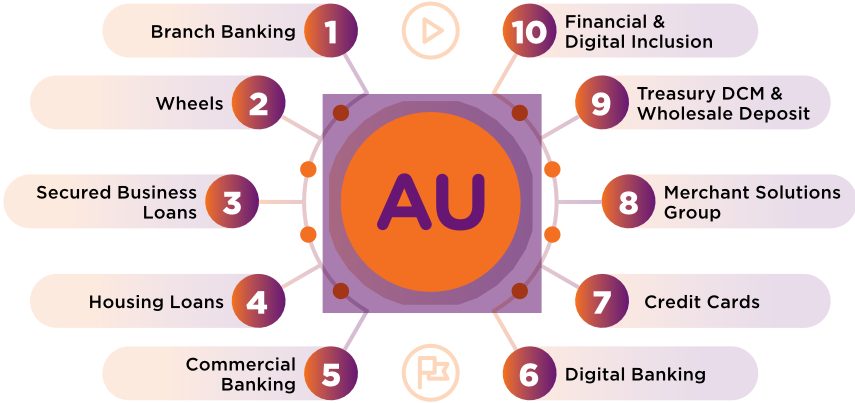

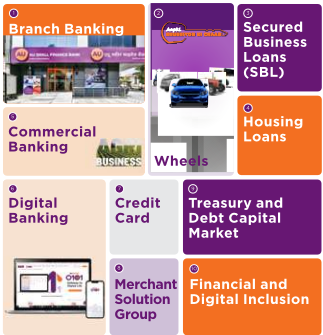

In [26]:
answer("Show me the business segments of AU Small Finance Bank in FY2023");

## Tightening the prompt
The advances answer above contained a **derived number**: the model divided top-20-borrower advances by their percentage share to get a "total credit exposure" that appears in no source, yet it still carried a citation. A citation doesn't prove a number is supported. The rule below allows only figures stated in the sources (plus simple differences or % changes with the calculation shown).

In [27]:
# Tightening the answer prompt: no derived quantities, no tangential points
ANSWER_PROMPT = """You are a financial analyst assistant answering questions about company annual reports.
Rules:
- Use ONLY the sources provided below. Never use outside knowledge.
- Only report numbers that appear in the sources. You MAY compute a simple difference or
  % change between two figures stated in the sources, and must show the calculation.
  NEVER derive new quantities (e.g. back-calculating a total from a percentage).
- Quote exact numbers with their units (₹ crore, %, etc.) and fiscal year.
- Cite every fact like [AU Small Finance Bank FY2024, p.148].
- Include only points that directly answer the question; leave out tangential data.
- If the sources don't contain the answer, reply: "I couldn't find this in the provided reports."
- Keep it concise: a direct answer first, then 1-3 supporting points."""

### Re-running with the tightened prompt
The derived figure is gone, and every number now appears directly in a source. The NPA answer reports the same figures as before(temperature 0), so results are repeatable.

In [28]:
answer("How did total advances change between FY23 and FY24?");

**Q: How did total advances change between FY23 and FY24?**

Total gross advances increased by **₹ 14,841 crore** (or **25.09%**) between FY23 and FY24.

**Supporting points:**
* **FY 2022-23:** Total Gross Advances were **₹ 59,158 crore** [Au Small Finance Bank FY2024, p.54] (also reported as 59,158 ₹ crore in [Au Small Finance Bank FY2023, p.73]).
* **FY 2023-24:** Total Gross Advances rose to **₹ 73,999 crore** [Au Small Finance Bank FY2024, p.54].
* **Calculation:** 
  $$\text{Absolute Change} = ₹ 73,999\text{ crore} - ₹ 59,158\text{ crore} = ₹ 14,841\text{ crore}$$
  $$\text{Percentage Change} = \left(\frac{₹ 14,841\text{ crore}}{₹ 59,158\text{ crore}}\right) \times 100 \approx 25.09\%$$
* *(Note: Total assigned loans also increased from ₹ 4,914 crore in FY 2022-23 to ₹ 8,176 crore in FY 2023-24 [Au Small Finance Bank FY2024, p.54]).*

model: gemini-3.8-flash | filters - company: None, years: ['2023', '2024']
  0.704 | table | FY2023 p73
  0.686 | table | FY2023 p260
  0.677 | text  | FY2024 p152
  0.672 | table | FY2024 p152
  0.669 | table | FY2023 p261
  0.668 | table | FY2023 p267
  0.666 | text  | FY2023 p267
  0.666 | table | FY2024 p54


In [29]:
answer("What was the gross NPA closing balance in FY 2023-24?");

**Q: What was the gross NPA closing balance in FY 2023-24?**

The gross NPA (Total Non-Performing Advances) closing balance in FY 2023-24 was **₹ 1,237.40 Crore** [Au Small Finance Bank FY2024, p.148].

**Supporting details:**
* **Breakdown by asset category:** The closing balance of ₹ 1,237.40 Crore consisted of ₹ 844.53 Crore in Sub-standard advances, ₹ 387.77 Crore in Doubtful advances, and ₹ 5.10 Crore in Loss advances [Au Small Finance Bank FY2024, p.148].
* **Movement during the year:** Gross NPAs started with an opening balance of ₹ 981.31 Crore, had additions of ₹ 1,698.19 Crore, and reductions of ₹ 1,442.10 Crore during FY 2023-24 [Au Small Finance Bank FY2024, p.148].
* **Gross NPA ratio:** Gross NPAs stood at 1.67% of gross advances as of March 31, 2024 [Au Small Finance Bank FY2024, p.122, p.149].

model: gemini-3.8-flash | filters - company: None, years: ['2024']
  0.755 | text  | FY2024 p149
  0.745 | table | FY2024 p148
  0.742 | table | FY2024 p148
  0.724 | table | FY2024 p54
  0.717 | text  | FY2024 p122
  0.715 | table | FY2024 p149
  0.711 | table | FY2024 p53
  0.710 | table | FY2024 p150


In [30]:
answer("What are the key risks highlighted by management in FY2025?");

**Q: What are the key risks highlighted by management in FY2025?**

In FY2025, management highlighted key risks monitored across its operations, which include credit, operational, market, liquidity, fraud, compliance, and cyber security risks, as well as emerging risks such as climate and data privacy [Au Small Finance Bank FY2025, p.74].

Supporting points:
- **Enterprise Risk Categories:** The Bank's enterprise risk model covers Credit Risk, Balance Sheet Risk, Liquidity & Market Risk, Compliance Risk, Operational Risk and Fraud Risk, People Risk, and IT & IS Risk [Au Small Finance Bank FY2025, p.22].
- **Cybersecurity Threats:** In advancing its digital journey, the Bank highlighted cyber risks such as malware, phishing, denial-of-service attacks, and data breaches that threaten systems, services, and sensitive information [Au Small Finance Bank FY2025, p.64].
- **Emerging Risks:** Specific emerging risks highlighted include Data Privacy, Cybersecurity & Fraud Risk, Climate Risk, and Social Media Risk (which presents reputational and operational risks) [Au Small Finance Bank FY2025, p.74].

model: gemini-3.8-flash | filters - company: None, years: ['2025']
  0.716 | text  | FY2025 p82
  0.702 | text  | FY2025 p64
  0.695 | text  | FY2025 p22
  0.689 | text  | FY2025 p64
  0.684 | text  | FY2025 p62
  0.682 | text  | FY2025 p74
  0.682 | text  | FY2025 p113
  0.678 | text  | FY2025 p74
